# Import

In [1]:
import glob
import numpy as np
import matplotlib.pyplot as plt
import dbetto
import lh5
import pandas as pd
import pygeomhades
import pygeomtools
from pygeomtools import write_pygeom
import pyg4ometry as pg4
from pyg4ometry import gdml
from pathlib import Path
from copy import deepcopy


from scipy.optimize import least_squares
from scipy.special import erf, erfc, xlogy
from scipy.stats import exponnorm

%matplotlib inline


In [2]:
import reboost
from reboost import hpge
from reboost.hpge import surface, psd
from reboost.shape import group
from reboost.math import functions
from reboost.math.stats import gaussian_sample
from reboost.utils import get_remage_detector_uids





In [3]:
from remage import remage_run



# functions

In [51]:
def find_matching_background_runs(db, detector, measure, campaign="c1"):
    configuration = db.hardware.configuration[detector][campaign]

    physics_runs = configuration[measure]
    background_runs = configuration["bkg"]

    matches = {}

    for run, data in sorted(physics_runs.items()):
        if not run.startswith("run"):
            continue

        card = data["daq_settings"]["flashcam"]["card_interface"]

        matching_bkg = [
            bkg_run
            for bkg_run, bkg_data in sorted(background_runs.items())
            if bkg_run.startswith("run")
            and bkg_data["daq_settings"]["flashcam"]["card_interface"] == card
        ]

        matches[run] = {
            "card_interface": card,
            "background_runs": matching_bkg,
        }

    return matches

In [52]:

def gaussian_bin_counts(edges, area, mu, sigma):
    z = (edges - mu) / (np.sqrt(2) * sigma)
    return area * 0.5 * np.diff(erf(z))


def left_tail_bin_counts(edges, area, mu, sigma, tau):
    cdf = exponnorm.sf(
        mu - edges,
        tau / sigma,
        loc=0,
        scale=sigma,
    )

    return area * np.maximum(np.diff(cdf), 0)


def step_primitive(x, mu, sigma):
    u = (x - mu) / (np.sqrt(2) * sigma)

    return 0.5 * (
        (x - mu) * erfc(u)
        - sigma * np.sqrt(2 / np.pi) * np.exp(-u**2)
    )


def am60_components(edges, parameters):
    (
        area, mu, sigma,
        tail_area, tau,
        background, step,
    ) = parameters

    peak = gaussian_bin_counts(edges, area, mu, sigma)
    tail = left_tail_bin_counts(
        edges, tail_area, mu, sigma, tau
    )

    continuum = (
        background * np.diff(edges)
        + step * np.diff(
            step_primitive(edges, mu, sigma)
        )
    )

    return {
        "gaussian": peak,
        "tail": tail,
        "continuum": continuum,
        "total": peak + tail + continuum,
    }


def am60_density(x, parameters):
    (
        area, mu, sigma,
        tail_area, tau,
        background, step,
    ) = parameters

    peak = (
        area / (np.sqrt(2 * np.pi) * sigma)
        * np.exp(-0.5 * ((x - mu) / sigma)**2)
    )

    tail = tail_area * exponnorm.pdf(
        mu - x,
        tau / sigma,
        loc=0,
        scale=sigma,
    )

    continuum = (
        background
        + step * 0.5 * erfc(
            (x - mu) / (np.sqrt(2) * sigma)
        )
    )

    return {
        "gaussian": peak,
        "tail": tail,
        "continuum": continuum,
        "total": peak + tail + continuum,
    }


def poisson_residuals(parameters, edges, counts):
    expected = np.maximum(
        am60_components(edges, parameters)["total"],
        1e-12,
    )

    deviance = 2 * (
        expected - counts
        + xlogy(counts, counts / expected)
    )

    return (
        np.sign(expected - counts)
        * np.sqrt(np.maximum(deviance, 0))
    )



In [67]:


def am100_components(edges, parameters):
    (
        N1, mu1,
        N2, mu2,
        N3, mu3,
        sigma,
        S1, S2,
        B,
    ) = parameters

    edges = np.asarray(edges, dtype=float)
    widths = np.diff(edges)

    def gaussian_counts(N, mu):
        return N * np.diff(ndtr((edges - mu) / sigma))

    def step_counts(S, mu):
        # Densità dello step: S * Phi((mu - E) / sigma)
        # Primitiva rispetto all'energia.
        z = (mu - edges) / sigma
        phi = np.exp(-0.5 * z**2) / np.sqrt(2 * np.pi)

        primitive = (
            (edges - mu) * ndtr(z)
            - sigma * phi
        )

        return S * np.maximum(np.diff(primitive), 0.0)

    g1 = gaussian_counts(N1, mu1)
    g2 = gaussian_counts(N2, mu2)
    g3 = gaussian_counts(N3, mu3)

    step1 = step_counts(S1, mu1)
    step2 = step_counts(S2, mu3)

    background = B * widths

    return {
        "gaussian_99": g1,
        "gaussian_101": g2,
        "gaussian_103": g3,
        "step_99": step1,
        "step_103": step2,
        "background": background,
        "total": g1 + g2 + g3 + step1 + step2 + background,
    }


def poisson_residuals_am100(parameters, edges, y):
    expected = am100_components(edges, parameters)["total"]
    expected = np.maximum(expected, np.finfo(float).tiny)

    # Residui della devianza di Poisson, inclusi i bin vuoti.
    deviance = expected - y
    positive = y > 0

    deviance[positive] += y[positive] * (
        np.log(y[positive]) - np.log(expected[positive])
    )

    return np.sign(y - expected) * np.sqrt(
        2.0 * np.maximum(deviance, 0.0)
    )


def fit_am_100(counts, bins, fit_range=(96.0, 106.0)):
    counts = np.asarray(counts, dtype=float)
    bins = np.asarray(bins, dtype=float)

    if counts.ndim != 1 or bins.ndim != 1:
        raise ValueError("counts e bins devono essere 1D.")

    if counts.size == 0 or bins.size != counts.size + 1:
        raise ValueError("Dimensioni istogramma incompatibili.")

    if not np.isfinite(counts).all() or np.any(counts < 0):
        raise ValueError("Conteggi non validi.")

    if not np.isfinite(bins).all() or np.any(np.diff(bins) <= 0):
        raise ValueError("Bordi non validi.")

    xmin, xmax = fit_range

    if not np.isfinite([xmin, xmax]).all() or xmin >= xmax:
        raise ValueError("Finestra di fit non valida.")

    indices = np.flatnonzero(
        (bins[:-1] >= xmin)
        & (bins[1:] <= xmax)
    )

    # 3 aree, 3 centroidi, 1 sigma, 2 step, 1 fondo.
    n_parameters = 10

    if indices.size <= n_parameters:
        raise ValueError("Troppi pochi bin nella finestra di fit.")

    first = indices[0]
    last = indices[-1] + 1

    edges = bins[first:last + 1]
    y = counts[first:last]

    if y.sum() <= 0:
        raise ValueError("Nessun conteggio nella finestra di fit.")

    if edges[0] >= 99.0 or edges[-1] <= 103.0:
        raise ValueError("La finestra deve includere tutti e tre i picchi.")

    widths = np.diff(edges)
    centers = (edges[:-1] + edges[1:]) / 2
    density = y / widths

    background = max(
        float(np.percentile(density, 10)),
        1e-3,
    )

    sigma_guess = 0.4

    def area_guess(mu):
        height = max(
            float(density[np.argmin(np.abs(centers - mu))])
            - background,
            1.0,
        )
        return height * np.sqrt(2 * np.pi) * sigma_guess

    # Ordine: N1, mu1, N2, mu2, N3, mu3, sigma, S1, S2, B.
    p0 = [
        area_guess(99.0), 99.0,
        area_guess(101.1), 101.1,
        area_guess(103.0), 103.0,
        sigma_guess,
        background * 0.5,
        background * 0.5,
        background,
    ]

    lower = [
        0.0, 98.5,
        0.0, 100.6,
        0.0, 102.5,
        0.05,
        0.0, 0.0,
        0.0,
    ]

    upper = [
        np.inf, 99.5,
        np.inf, 101.6,
        np.inf, 103.5,
        1.2,
        np.inf, np.inf,
        np.inf,
    ]

    fit = least_squares(
        poisson_residuals_am100,
        p0,
        bounds=(lower, upper),
        args=(edges, y),
        x_scale="jac",
        max_nfev=20000,
    )

    if not fit.success:
        raise RuntimeError(f"Fit fallito: {fit.message}")

    rank = np.linalg.matrix_rank(fit.jac)
    full_rank = rank == n_parameters

    covariance = (
        np.linalg.pinv(fit.jac.T @ fit.jac)
        if full_rank
        else np.full((n_parameters, n_parameters), np.nan)
    )

    errors = np.sqrt(
        np.maximum(np.diag(covariance), 0.0)
    )

    peak_indices = [0, 2, 4]
    areas = fit.x[peak_indices].copy()

    if not np.isfinite(areas).all() or np.any(areas <= 0):
        raise ValueError("Aree dei picchi non valide.")

    return {
        "parameter_names": [
            "N1", "mu1",
            "N2", "mu2",
            "N3", "mu3",
            "sigma",
            "S1", "S2",
            "B",
        ],
        "parameters": fit.x,
        "errors": errors,
        "covariance": covariance,
        "area_peak": areas,
        "area_peak_errors": errors[peak_indices],
        "mu": fit.x[[1, 3, 5]],
        "mu_errors": errors[[1, 3, 5]],
        "fwhm": 2.35482 * fit.x[6],
        "fwhm_error": 2.35482 * errors[6],
        "edges": edges,
        "counts": y,
        "components": am100_components(edges, fit.x),
        "residuals": fit.fun,
        "deviance": float(np.sum(fit.fun**2)),
        "ndof": y.size - n_parameters,
        "full_rank": full_rank,
        "at_bounds": bool(np.any(fit.active_mask != 0)),
        "active_mask": fit.active_mask,
        "nfev": fit.nfev,
        "message": fit.message,
    }

import numpy as np
import matplotlib.pyplot as plt
from scipy.special import ndtr


def am100_density(x, parameters):
    (
        N1, mu1,
        N2, mu2,
        N3, mu3,
        sigma,
        S1, S2,
        B,
    ) = parameters

    x = np.asarray(x, dtype=float)

    def gaussian(N, mu):
        return (
            N / (np.sqrt(2 * np.pi) * sigma)
            * np.exp(-0.5 * ((x - mu) / sigma)**2)
        )

    g1 = gaussian(N1, mu1)
    g2 = gaussian(N2, mu2)
    g3 = gaussian(N3, mu3)

    step1 = S1 * ndtr((mu1 - x) / sigma)
    step2 = S2 * ndtr((mu3 - x) / sigma)
    background = np.full_like(x, B)

    return {
        "gaussian_99": g1,
        "gaussian_101": g2,
        "gaussian_103": g3,
        "step_99": step1,
        "step_103": step2,
        "background": background,
        "total": g1 + g2 + g3 + step1 + step2 + background,
    }


# ============================================================
# FIT FIGURE: EXACTLY (5, 3)
# ============================================================

def plot_am100_fit(result, detector, run, meta, dpi=300):
    fig, (ax, ax_res) = plt.subplots(
        2, 1,
        figsize=(5, 3),
        sharex=True,
        height_ratios=[3, 1],
        layout="constrained",
        dpi=dpi,
    )

    edges = result["edges"]
    centers = (edges[:-1] + edges[1:]) / 2
    widths = np.diff(edges)
    width = widths[0]

    if not np.allclose(widths, width):
        plt.close(fig)
        raise ValueError("Questo plot richiede bin di larghezza uniforme.")

    x = np.linspace(edges[0], edges[-1], 3000)
    smooth = am100_density(x, result["parameters"])

    ax.stairs(
        result["counts"],
        edges,
        color="navy",
        linewidth=0.8,
        label="Data",
    )

    for key, label, color, linestyle in [
        ("total", "Total", "darkorange", "-"),
        ("gaussian_99", "Gaussian 99 keV", "crimson", "--"),
        ("gaussian_101", "Gaussian 101.1 keV", "deepskyblue", "--"),
        ("gaussian_103", "Gaussian 103 keV", "green", "--"),
        ("step_99", "Step 99 keV", "purple", "--"),
        ("step_103", "Step 103 keV", "brown", "--"),
        ("background", "Background", "gray", "--"),
    ]:
        curve = smooth[key] * width

        ax.plot(
            x,
            np.where(curve > 0, curve, np.nan),
            color=color,
            linestyle=linestyle,
            linewidth=0.9,
            label=label,
        )

    ax.set_yscale("log")

    positive = result["counts"][result["counts"] > 0]
    ymax = max(
        result["counts"].max(),
        smooth["total"].max() * width,
    )

    #ax.set_ylim(
    #    max(0.1, min(100.0, positive.min() * 0.5)),
   #     ymax * 2,
   # )

    ax.set_ylim(
        0.01, 2e3
    )

    p = result["parameters"]
    errors = result["errors"]

    text = (
        rf"$A_1={p[0]:.0f}\pm{errors[0]:.0f}$ counts" "\n"
        rf"$\mu_1={p[1]:.4f}\pm{errors[1]:.4f}$ keV" "\n"
        rf"$A_2={p[2]:.0f}\pm{errors[2]:.0f}$ counts" "\n"
        rf"$\mu_2={p[3]:.4f}\pm{errors[3]:.4f}$ keV" "\n"
        rf"$A_3={p[4]:.0f}\pm{errors[4]:.0f}$ counts" "\n"
        rf"$\mu_3={p[5]:.4f}\pm{errors[5]:.4f}$ keV" "\n"
        rf"$\sigma={p[6]:.4f}\pm{errors[6]:.4f}$ keV" "\n"
        rf"$S_1={p[7]:.1f}\pm{errors[7]:.1f}$ counts/keV" "\n"
        rf"$S_2={p[8]:.1f}\pm{errors[8]:.1f}$ counts/keV" "\n"
        rf"$B={p[9]:.1f}\pm{errors[9]:.1f}$ counts/keV" "\n"
        f"FWHM={result['fwhm']:.4f}"
        f" ± {result['fwhm_error']:.4f} keV\n"
        f"D/ndof={result['deviance']:.1f}/{result['ndof']}"
    )

    ax.text(
        0.98, 0.97,
        text,
        transform=ax.transAxes,
        ha="right",
        va="top",
        fontsize=5,
        color="navy",
        bbox={
            "facecolor": "white",
            "edgecolor": "none",
            "alpha": 0.85,
            "pad": 2,
        },
    )

    pos = meta["source_position"]

    ax.set_title(
        f"{detector}/{run} | "
        f"r={float(pos['r_in_mm']):g}, "
        f"z={float(pos['z_in_mm']):g} mm, "
        f"φ={float(pos['phi_in_deg']):g}° | "
        f"t={float(meta['run_live_time_in_s']) / 3600:g} h",
        fontsize=7,
    )

    ax.set_ylabel(f"Counts / {width:g} keV", fontsize=7)
    ax.legend(fontsize=5.5, loc="upper left")

    ax_res.axhline(
        0,
        color="gray",
        linestyle="--",
        linewidth=0.6,
    )

    ax_res.plot(
        centers,
        result["residuals"],
        ".",
        color="navy",
        markersize=2,
    )

    ax_res.set_ylabel("Deviance\nresidual", fontsize=6)
    ax_res.set_xlabel("Energy (keV)", fontsize=7)
    ax_res.set_xlim(edges[0], edges[-1])

    for axis in (ax, ax_res):
        axis.tick_params(labelsize=6)

    return fig



In [57]:

def am60_components(edges, parameters):
    area, mu, sigma, tail_area, tau, S = parameters

    edges = np.asarray(edges, dtype=float)

    gaussian = area * np.maximum(
        np.diff(ndtr((edges - mu) / sigma)),
        0.0,
    )

    distribution = exponnorm(
        tau / sigma,
        loc=mu,
        scale=sigma,
    )

    cdf = distribution.cdf(edges)
    sf = distribution.sf(edges)

    probability = np.where(
        cdf[:-1] > 0.5,
        sf[:-1] - sf[1:],
        cdf[1:] - cdf[:-1],
    )

    tail = tail_area * np.maximum(probability, 0.0)

    z = (mu - edges) / sigma
    phi = np.exp(-0.5 * z**2) / np.sqrt(2 * np.pi)

    primitive = (
        (edges - mu) * ndtr(z)
        - sigma * phi
    )

    step = S * np.maximum(
        np.diff(primitive), 0.0
    )

    return {
        "gaussian": gaussian,
        "tail": tail,
        "step": step,
        "total": gaussian + tail + step,
    }


def am60_density(x, parameters):
    area, mu, sigma, tail_area, tau, S = parameters

    x = np.asarray(x, dtype=float)

    gaussian = (
        area / (np.sqrt(2 * np.pi) * sigma)
        * np.exp(-0.5 * ((x - mu) / sigma)**2)
    )

    tail = tail_area * exponnorm.pdf(
        x,
        tau / sigma,
        loc=mu,
        scale=sigma,
    )

    step = S * ndtr((mu - x) / sigma)

    return {
        "gaussian": gaussian,
        "tail": tail,
        "step": step,
        "total": gaussian + tail + step,
    }
    
def am60_density(x, parameters):
    area, mu, sigma, tail_area, tau, S = parameters

    x = np.asarray(x, dtype=float)

    gaussian = (
        area / (np.sqrt(2 * np.pi) * sigma)
        * np.exp(-0.5 * ((x - mu) / sigma)**2)
    )

    tail = tail_area * exponnorm.pdf(
        x,
        tau / sigma,
        loc=mu,
        scale=sigma,
    )

    step = S * ndtr((mu - x) / sigma)

    return {
        "gaussian": gaussian,
        "tail": tail,
        "step": step,
        "total": gaussian + tail + step,
    }


# ============================================================
# POISSON DEVIANCE RESIDUALS
# ============================================================

def poisson_residuals(parameters, edges, counts):
    expected = np.maximum(
        am60_components(edges, parameters)["total"],
        np.finfo(float).tiny,
    )

    half_deviance = expected.copy()
    positive = counts > 0

    observed = counts[positive]
    predicted = expected[positive]

    delta = (predicted - observed) / observed

    near = np.abs(delta) < 0.01
    terms = np.empty_like(delta)

    # Stable expansion near predicted == observed.
    d = delta[near]

    terms[near] = d**2 * (
        0.5 - d / 3 + d**2 / 4
        - d**3 / 5 + d**4 / 6
    )

    terms[~near] = (
        delta[~near]
        + np.log(observed[~near])
        - np.log(predicted[~near])
    )

    half_deviance[positive] = observed * terms

    # Positive residual: data exceed the model.
    return np.sign(counts - expected) * np.sqrt(
        2.0 * np.maximum(half_deviance, 0.0)
    )


# ============================================================
# FIT CALIBRATED RAW COUNTS
# ============================================================

def fit_am60(counts, bins, fit_range=(57, 70)):
    counts = np.asarray(counts, dtype=float)
    bins = np.asarray(bins, dtype=float)

    if counts.ndim != 1 or bins.ndim != 1:
        raise ValueError("counts e bins devono essere 1D.")

    if counts.size == 0 or bins.size != counts.size + 1:
        raise ValueError("Dimensioni istogramma incompatibili.")

    if not np.isfinite(counts).all() or np.any(counts < 0):
        raise ValueError("Conteggi non validi.")

    if (
        not np.isfinite(bins).all()
        or np.any(np.diff(bins) <= 0)
    ):
        raise ValueError("Bordi non validi.")

    xmin, xmax = fit_range

    if not np.isfinite([xmin, xmax]).all() or xmin >= xmax:
        raise ValueError("Finestra di fit non valida.")

    indices = np.flatnonzero(
        (bins[:-1] >= xmin)
        & (bins[1:] <= xmax)
    )

    n_parameters = len(PARAMETER_NAMES)

    if indices.size <= n_parameters:
        raise ValueError(
            "Troppi pochi bin per un fit con 6 parametri."
        )

    first = indices[0]
    last = indices[-1] + 1

    edges = bins[first:last + 1]
    y = counts[first:last]

    if y.sum() <= 0:
        raise ValueError(
            "Nessun conteggio nella finestra di fit."
        )

    if not (edges[0] < 59.54 < edges[-1]):
        raise ValueError(
            "La finestra deve includere il picco a 59.54 keV."
        )

    centers = (edges[:-1] + edges[1:]) / 2
    density = y / np.diff(edges)

    mu_guess = 59.54
    sigma_guess = 0.3

    # Estimate the step plateau below the peak.
    low_energy = centers < 58.5

    step_guess = max(
        float(np.percentile(density[low_energy], 20))
        if np.any(low_energy)
        else float(np.percentile(density, 20)),
        1e-3,
    )

    index = np.argmin(np.abs(centers - mu_guess))

    height = max(
        float(density[index]) - 0.5 * step_guess,
        1.0,
    )

    area_guess = (
        height * np.sqrt(2 * np.pi) * sigma_guess
    )

    # area_peak, mu, sigma, area_tail, tau, step
    p0 = [
        area_guess,
        mu_guess,
        sigma_guess,
        area_guess * 0.02,
        1.0,
        step_guess,
    ]

    lower = [
        0.0,
        58.8,
        0.05,
        0.0,
        0.05,
        0.0,
    ]

    upper = [
        np.inf,
        60.3,
        1.2,
        np.inf,
        10.0,
        np.inf,
    ]

    fit = least_squares(
        poisson_residuals,
        p0,
        bounds=(lower, upper),
        args=(edges, y),
        x_scale="jac",
        max_nfev=20000,
    )

    if not fit.success:
        raise RuntimeError(f"Fit fallito: {fit.message}")

    # Column scaling reduces sensitivity of the rank check
    # to the very different parameter units and magnitudes.
    column_norms = np.linalg.norm(fit.jac, axis=0)
    safe_norms = np.where(column_norms > 0, column_norms, 1.0)
    scaled_jacobian = fit.jac / safe_norms

    full_rank = (
        np.linalg.matrix_rank(scaled_jacobian)
        == n_parameters
    )

    if full_rank:
        _, singular_values, vt = np.linalg.svd(
            scaled_jacobian,
            full_matrices=False,
        )

        scaled_covariance = (
            vt.T / singular_values**2
        ) @ vt

        covariance = (
            scaled_covariance
            / safe_norms[:, None]
            / safe_norms[None, :]
        )

    else:
        covariance = np.full(
            (n_parameters, n_parameters),
            np.nan,
        )

    errors = np.sqrt(
        np.maximum(np.diag(covariance), 0.0)
    )

    if not np.isfinite(fit.x).all() or fit.x[0] <= 0:
        raise ValueError(
            "Parametri o area gaussiana non validi."
        )

    result = {
        "parameter_names": PARAMETER_NAMES.copy(),
        "parameters": fit.x,
        "errors": errors,
        "covariance": covariance,

        "area_peak": fit.x[0],
        "area_peak_error": errors[0],

        "mu": fit.x[1],
        "mu_error": errors[1],

        "sigma": fit.x[2],
        "sigma_error": errors[2],

        "area_tail": fit.x[3],
        "area_tail_error": errors[3],

        "tau": fit.x[4],
        "tau_error": errors[4],

        "step": fit.x[5],
        "step_error": errors[5],

        # FWHM of the Gaussian component only.
        "fwhm": 2.35482 * fit.x[2],
        "fwhm_error": 2.35482 * errors[2],

        "edges": edges,
        "counts": y,
        "components": am60_components(edges, fit.x),
        "residuals": fit.fun,
        "deviance": float(np.sum(fit.fun**2)),
        "ndof": y.size - n_parameters,

        "full_rank": full_rank,
        "at_bounds": bool(np.any(fit.active_mask != 0)),
        "active_mask": fit.active_mask,
        "nfev": fit.nfev,
        "message": fit.message,
    }

    for name, value, error in zip(
        PARAMETER_NAMES,
        fit.x,
        errors,
    ):
        print(f"{name} = {value:.6g} ± {error:.3g}")

    print(
        f"FWHM gaussiana = {result['fwhm']:.5f}"
        f" ± {result['fwhm_error']:.3g} keV\n"
        f"Deviance / ndof = "
        f"{result['deviance']:.2f}/{result['ndof']}"
    )

    if result["at_bounds"]:
        names_at_bounds = [
            name
            for name, active in zip(
                PARAMETER_NAMES,
                fit.active_mask,
            )
            if active != 0
        ]

        print(
            "CHECK FIT: parametri al limite: "
            + ", ".join(names_at_bounds)
        )

    if not full_rank:
        print("CHECK FIT: incertezze non identificabili.")

    return result


# ============================================================
# FIT FIGURE: (5, 3)
# ============================================================

def plot_am60_fit(result, detector, run, meta, dpi=300):
    edges = result["edges"]
    widths = np.diff(edges)
    centers = (edges[:-1] + edges[1:]) / 2

    uniform = np.allclose(widths, widths[0])

    if uniform:
        values = result["counts"]
        curve_scale = widths[0]
        ylabel = f"Counts / {widths[0]:g} keV"
    else:
        values = result["counts"] / widths
        curve_scale = 1.0
        ylabel = "Counts / keV"

    x = np.linspace(
        edges[0], edges[-1], 3000
    )

    smooth = am60_density(
        x, result["parameters"]
    )

    fig, (ax, ax_res) = plt.subplots(
        2, 1,
        figsize=(5, 3),
        sharex=True,
        height_ratios=[3, 1],
        layout="constrained",
        dpi=dpi,
    )

    ax.stairs(
        values,
        edges,
        color="navy",
        linewidth=0.8,
        label="Data",
    )

    for key, label, color, linestyle in [
        ("total", "Total fit", "darkorange", "-"),
        ("gaussian", "Gaussian", "crimson", "--"),
        ("tail", "Right tail", "deepskyblue", "--"),
        ("step", "Step", "purple", "--"),
    ]:
        curve = smooth[key] * curve_scale

        ax.plot(
            x,
            np.where(curve > 0, curve, np.nan),
            color=color,
            linestyle=linestyle,
            linewidth=0.9,
            label=label,
        )

    ax.set_yscale("log")

    positive = values[values > 0]

    ax.set_ylim(
        min(0.5, positive.min() / 2),
        max(
            values.max(),
            smooth["total"].max() * curve_scale,
        ) * 2,
    )

    labels = [
        "A_G", "mu", "sigma",
        "A_right", "tau_right", "S",
    ]

    units = [
        "counts", "keV", "keV",
        "counts", "keV", "counts/keV",
    ]

    lines = [
        f"{label}={value:.4g} ± {error:.2g} {unit}"
        for label, value, error, unit in zip(
            labels,
            result["parameters"],
            result["errors"],
            units,
        )
    ]

    lines += [
        f"FWHM={result['fwhm']:.4f}"
        f" ± {result['fwhm_error']:.3g} keV",
        f"D/ndof={result['deviance']:.1f}/{result['ndof']}",
    ]

    ax.text(
        0.98, 0.97,
        "\n".join(lines),
        transform=ax.transAxes,
        ha="right",
        va="top",
        fontsize=5,
        color="navy",
        bbox=dict(
            facecolor="white",
            edgecolor="none",
            alpha=0.85,
            pad=2,
        ),
    )

    pos = meta["source_position"]

    ax.set_title(
        f"{detector}/{run} | "
        f"r={float(pos['r_in_mm']):g}, "
        f"z={float(pos['z_in_mm']):g} mm, "
        f"φ={float(pos['phi_in_deg']):g}° | "
        f"t={float(meta['run_live_time_in_s']) / 3600:g} h",
        fontsize=7,
    )

    ax.set_ylabel(ylabel, fontsize=7)
    ax.legend(
        fontsize=5.5,
        loc="upper left",
        frameon=False,
    )

    ax_res.axhline(
        0,
        color="gray",
        linestyle="--",
        linewidth=0.6,
    )

    ax_res.plot(
        centers,
        result["residuals"],
        ".",
        color="navy",
        markersize=2,
    )

    ax_res.set_ylabel(
        "Deviance\nresidual",
        fontsize=6,
    )

    ax_res.set_xlabel(
        "Energy (keV)",
        fontsize=7,
    )

    ax_res.set_xlim(
        edges[0], edges[-1]
    )

    for axis in (ax, ax_res):
        axis.tick_params(labelsize=6)

    return fig



# Metadata HADES

In [11]:
detector = "V06659A"
version = "v1.2.1"

#detector = "V08682B"
#version = "v1.1.0"

measure = "am_HS6_top_dlt"
run = 1
campaign = "c1"



In [12]:
run_key = f"run{int(run):04d}"   # run0002: metadati
run_tag = f"r{int(run):03d}"     # r002: file LH5

In [13]:
metadata_path = "/global/u2/r/ritaferi/HADES_DATA/hades-metadata"
db = dbetto.TextDB(metadata_path)


In [14]:
db_data = db.hardware.configuration[detector]["c1"][measure]['run0001']

In [15]:
#db_bkg = db.hardware.configuration[detector]["c1"]["bkg"][f'run0001']

# data and background

In [16]:
import glob
#measure = 'th_HS2_top_psa'

def find_same_card_runs(
    db,
    detector,
    version=version,
    measure=measure,
    campaign=campaign,
):
    base = (
        "/global/cfs/cdirs/m2676/data/teststands/hades/"
        f"prodenv/ref/{version}/generated/tier/hit/"
        f"{detector}/{campaign}"
    )

    print(base)

    def get_available_runs(measurement):
        try:
            config = (
                db.hardware.configuration[detector]
                [campaign][measurement]
            )
        except (KeyError, FileNotFoundError):
            print(
                f"{detector}: metadata missing for "
                f"{campaign}/{measurement}."
            )
            return {}

        available = {}

        print(f"\n--- {detector} / {measurement}: all cards ---")

        for run in sorted(config.keys()):
            if not (
                run.startswith("run")
                and run[3:].isdigit()
            ):
                continue

            try:
                meta = config[run]

                card = (
                    meta["daq_settings"]["flashcam"]
                    ["card_interface"]
                )

                if card is None or card == "":
                    raise ValueError("Empty card_interface.")

                # Print even if physics files are unavailable.
                print(
                    f"{detector}/{measurement}/{run} | "
                    f"card_interface: {card}"
                )

                # run0001 -> r001
                run_tag = f"r{int(run[3:]):03d}"

                pattern = (
                    f"{base}/{measurement}/"
                    f"char_data-{detector}-{measurement}-"
                    f"{run_tag}-*-tier_hit.lh5"
                )

                files = sorted(glob.glob(pattern))

                if not files:
                    print(
                        f"  No physics files found: "
                        f"{measurement}/{run} excluded from pairing."
                    )
                    continue

                available[run] = {
                    "card_interface": card,
                    "metadata": meta,
                    "files": files,
                }

            except (
                KeyError,
                FileNotFoundError,
                TypeError,
                ValueError,
            ) as exc:
                print(
                    f"Skipping {detector}/{measurement}/{run}: {exc}"
                )

        return available

    measurement_runs = get_available_runs(measure)
    background_runs = get_available_runs("bkg")

    pairs = []

    print(f"\n--- {detector}: matching pairs ---")

    for run_measure, info_measure in measurement_runs.items():
        for run_background, info_background in background_runs.items():
            if (
                info_measure["card_interface"]
                != info_background["card_interface"]
            ):
                continue

            pairs.append({
                "detector": detector,
                "measurement_run": run_measure,
                "background_run": run_background,
                "card_interface": info_measure["card_interface"],
                "measurement_files": info_measure["files"],
                "background_files": info_background["files"],
                "measurement_metadata": info_measure["metadata"],
                "background_metadata": info_background["metadata"],
            })

            print(
                f"{measure}/{run_measure} ↔ bkg/{run_background}\n"
                f"  Card: {info_measure['card_interface']}\n"
                f"  Measurement files: {len(info_measure['files'])}\n"
                f"  Background files: {len(info_background['files'])}"
            )

    if not pairs:
        print(
            "No pairs with matching card_interface "
            "and available physics files."
        )

    return pairs

In [17]:
pairs = find_same_card_runs(
    db,
    detector=detector,
    version=version,
    measure=measure,
    campaign=campaign,
)

# File della prima coppia compatibile.
if pairs:
    file_names = pairs[0]["measurement_files"]
    file_names_bkg = pairs[0]["background_files"]

/global/cfs/cdirs/m2676/data/teststands/hades/prodenv/ref/v1.2.1/generated/tier/hit/V06659A/c1

--- V06659A / am_HS6_top_dlt: all cards ---
V06659A/am_HS6_top_dlt/run0001 | card_interface: efb2

--- V06659A / bkg: all cards ---
V06659A/bkg/run0002 | card_interface: efb3

--- V06659A: matching pairs ---
No pairs with matching card_interface and available physics files.


In [18]:
from collections.abc import Mapping
from pprint import pformat


def flatten_metadata(obj, prefix=""):
    result = {}

    if isinstance(obj, Mapping):
        for key, value in obj.items():
            path = f"{prefix}.{key}" if prefix else str(key)
            result.update(flatten_metadata(value, path))
    else:
        result[prefix] = obj

    return result


config = db.hardware.configuration[detector][campaign]["bkg"]

metadata = {
    run: flatten_metadata(config[run])
    for run in ["run0001", "run0002"]#, "run0003"]
}

fields = sorted({
    field
    for values in metadata.values()
    for field in values
})

for field in fields:
    values = {
        run: pformat(meta.get(field, "<missing>"))
        for run, meta in metadata.items()
    }

    if len(set(values.values())) > 1:
        print(f"\n{field}")

        for run, value in values.items():
            print(f"  {run}: {value}")

KeyError: 'run0001'

# Data and plot

In [19]:
background_run_tag = 'r002'
# qui devo mttere il background che ha la stessa card interface perche rappresenta ka misura di static tble aassoociata. in questo caso abbiamo lo scanning table

In [20]:
file_pattern = (
    f"/global/cfs/cdirs/m2676/data/teststands/hades/prodenv/ref/"
    f"{version}/generated/tier/hit/{detector}/{campaign}/{measure}/"
    f"char_data-{detector}-{measure}-{run_tag}-*.lh5"
)


file_background = (
    f"/global/cfs/cdirs/m2676/data/teststands/hades/prodenv/ref/"
    f"{version}/generated/tier/hit/{detector}/{campaign}/bkg/"
    f"char_data-{detector}-bkg-{background_run_tag}-*-tier_hit.lh5"
)




In [21]:
file_names = sorted(glob.glob(file_pattern))
file_names_bkg = sorted(glob.glob(file_background))


In [22]:
if not file_names:
    raise FileNotFoundError(
        f"Nessun file trovato per {detector}, {measure}, {run_key}:\n"
        f"{file_pattern}"
    )

print(f"{run_key}: {len(file_names)} file trovati")




if not file_names_bkg:
    raise FileNotFoundError(file_background)
print(f"File background trovati: {len(file_names_bkg)}")

run0001: 36 file trovati
File background trovati: 30


In [23]:
emin = 0
emax = 7000
nbins = 70000
bins = np.linspace(emin, emax, nbins + 1)


In [24]:
background_run_tag

'r002'

In [25]:

force_rebuild = False

background_run_key = "run0001"

spectrum_dir = (
    Path("raw_energy_spectrum")
    / version
    / campaign
    / detector
)

spectrum_dir.mkdir(parents=True, exist_ok=True)

spectrum_path = spectrum_dir / (
    f"{detector}_{measure}_{run_key}_spectrum.npz"
)

background_path = spectrum_dir / (
    f"{detector}_bkg_{background_run_key}_spectrum.npz"
)

# Stessi bordi per misura e background.
bins = np.linspace(emin, emax, nbins + 1)


# ============================================================
# BACKGROUND FILES
# ============================================================

file_background = (
    f"/global/cfs/cdirs/m2676/data/teststands/hades/prodenv/ref/"
    f"{version}/generated/tier/hit/{detector}/{campaign}/bkg/"
    f"char_data-{detector}-bkg-{background_run_tag}-*-tier_hit.lh5"
)

file_names_bkg = sorted(glob.glob(file_background))


# ============================================================
# LOAD OR BUILD RAW HISTOGRAM
# ============================================================

def load_or_build_spectrum(path, files, bins, force_rebuild=False):
    if path.exists() and not force_rebuild:
        print(f"Carico: {path}")

        with np.load(path, allow_pickle=False) as spectrum:
            counts = np.asarray(spectrum["counts"]).copy()
            saved_bins = np.asarray(spectrum["bins"]).copy()

        if (
            saved_bins.shape == bins.shape
            and np.allclose(saved_bins, bins, rtol=0, atol=1e-8)
            and counts.shape == (len(bins) - 1,)
        ):
            return counts

        print("Binning incompatibile: rigenero.")

    if not files:
        raise FileNotFoundError(
            f"Nessun file LH5 disponibile per creare {path}"
        )

    print(f"Creo: {path}")

    counts = np.zeros(len(bins) - 1, dtype=np.int64)

    # Legge un file alla volta per limitare l'uso di memoria.
    for index, filename in enumerate(files, start=1):
        print(f"  File {index}/{len(files)}")

        energy = lh5.read(
            "hit/cuspEmax_ctc_cal",
            str(filename),
        ).nda

        partial_counts, _ = np.histogram(energy, bins=bins)
        counts += partial_counts

        del energy, partial_counts

    np.savez_compressed(
        path,
        counts=counts,
        bins=bins,
    )

    return counts






In [26]:
counts_data = load_or_build_spectrum(
    spectrum_path,
    file_names,
    bins,
    force_rebuild,
)

counts_bkg = load_or_build_spectrum(
    background_path,
    file_names_bkg,
    bins,
    force_rebuild,
)

Carico: raw_energy_spectrum/v1.2.1/c1/V06659A/V06659A_am_HS6_top_dlt_run0001_spectrum.npz
Carico: raw_energy_spectrum/v1.2.1/c1/V06659A/V06659A_bkg_run0001_spectrum.npz


In [27]:


# ============================================================
# LIVE-TIME NORMALIZATION
# ============================================================

meta_data = (
    db.hardware.configuration[detector]
    [campaign][measure][run_key]
)

background_run_key = 'r0002'
meta_bkg = (
    db.hardware.configuration[detector]
    [campaign]["bkg"][background_run_key]
)

time_data = float(meta_data["run_live_time_in_s"])
time_bkg = float(meta_bkg["run_live_time_in_s"])

if (
    not np.isfinite([time_data, time_bkg]).all()
    or time_data <= 0
    or time_bkg <= 0
):
    raise ValueError("Live time non valido.")

alpha = time_data / time_bkg

counts_bkg_scaled = alpha * counts_bkg
counts_subtracted = counts_data - counts_bkg_scaled

# Incertezza statistica della sottrazione,
# assumendo conteggi Poisson indipendenti e live time esatti.
counts_subtracted_error = np.sqrt(
    counts_data + alpha**2 * counts_bkg
)

print(f"Measurement live time: {time_data:g} s")
print(f"Background live time: {time_bkg:g} s")
print(f"Background scale factor: {alpha:.6g}")


KeyError: 'r0002'

NameError: name 'counts_bkg_scaled' is not defined

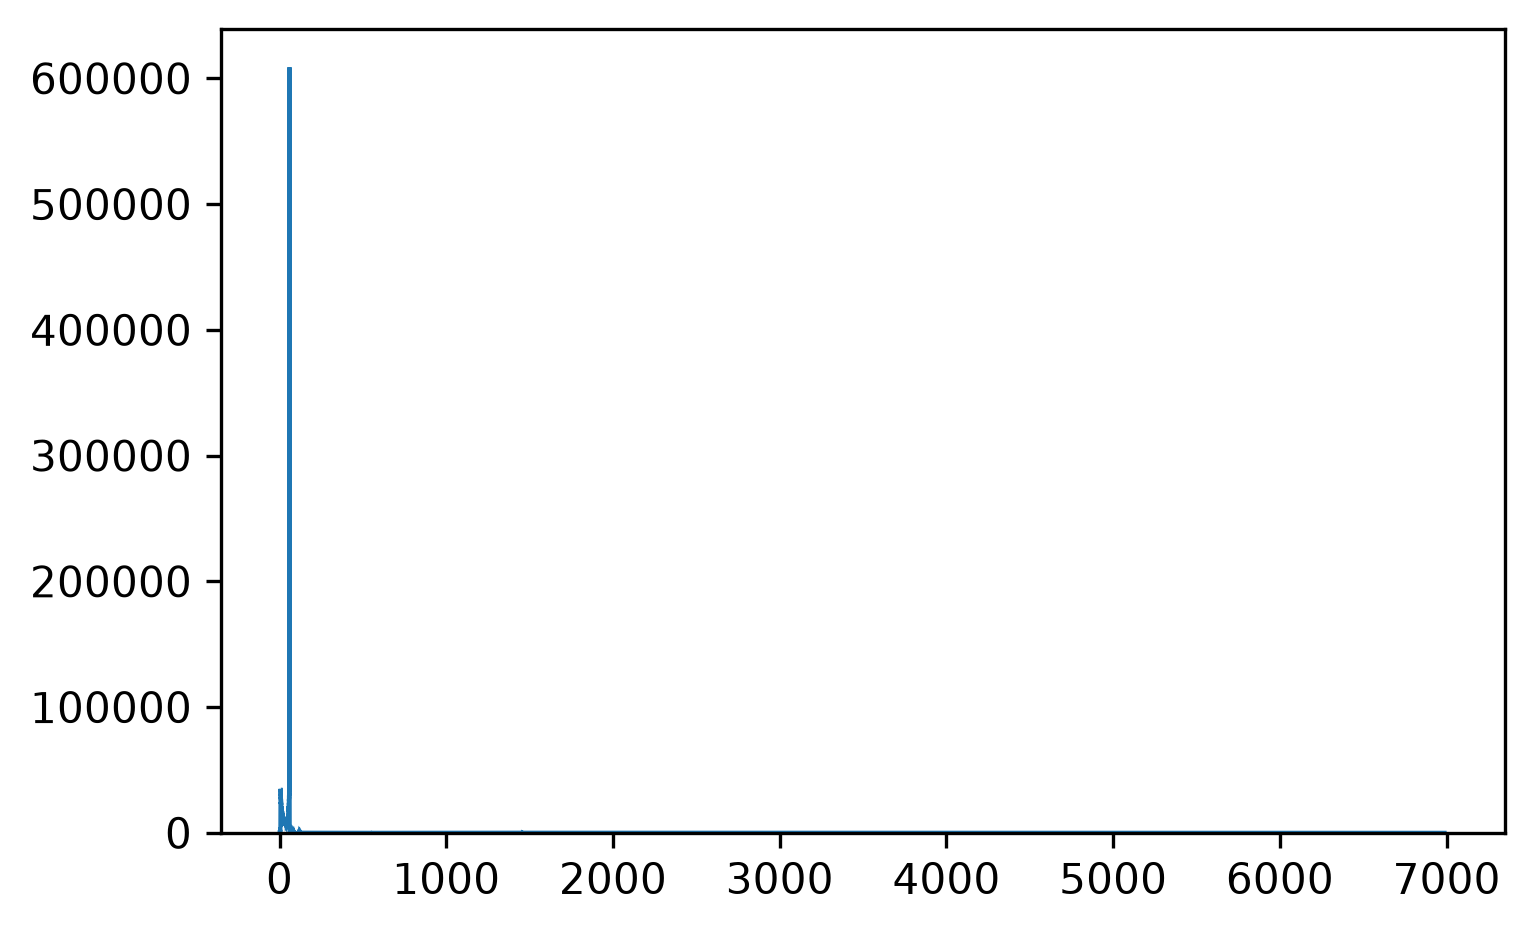

In [28]:

# ============================================================
# PLOT
# ============================================================

fig, ax = plt.subplots(
    figsize=(5, 3),
    dpi=300,
    layout="constrained",
)

ax.stairs(
    counts_data,
    bins,
    #color="navy",
    label=f"Data — {run_key}",
)

ax.stairs(
    counts_bkg_scaled,
    bins,
    color="orange",
    label=f"Background — {background_run_key}, scaled",
)

ax.set_yscale("log")
ax.set_xlabel("Energy (keV)")
ax.set_ylabel(f"Counts / {bins[1] - bins[0]:.2f} keV")
ax.legend(frameon=False, fontsize=8)
ax.set_xlim(0, 200)
#ax.set_xlim(52,62)
#ax.set_ylim(1e4, 1e6)
plt.show()

In [29]:
print(f"Dimensione file: {spectrum_path.stat().st_size / 1024:.1f} KiB")

Dimensione file: 148.2 KiB


In [30]:
# ============================================================
# ANNOTAZIONE
# ============================================================
#detector = "V03421A"
source = db_data["source_position"]
card = db_data["daq_settings"]["flashcam"]["card_interface"]

annotation_measure = (
    f"Detector: {db_data['detector']}\n"
    f"Measure: {db_data['measurement']}\n"
    f"Run: {db_data['run']} "
    f"(T = {db_data['run_live_time_in_s'] / 3600:g} h)\n"
    f"Card interface: {card}\n"
    f"Voltage: {db_data['high_voltage_in_V']} V\n"
    f"z = {source['z_in_mm']:g} mm\n"
    f"r = {source['r_in_mm']:g} mm\n"
    f"φ = {source['phi_in_deg']:g}°"
)
annotation_measure

'Detector: V06659A\nMeasure: am_HS6_top_dlt\nRun: run0001 (T = 6 h)\nCard interface: efb2\nVoltage: 3000 V\nz = 198 mm\nr = 0 mm\nφ = 0°'

In [31]:
# Mantengo le energie che hai indicato
peaks = {
    "gamma_59p9keV": 59.9,
    "gamma_99keV": 99.0,
    "gamma_103keV": 103.0,
    "gamma_123p1keV": 123.1,
    "gamma_125p3keV": 125.3,
    "gamma_208p1keV": 208.1,
    "gamma_335p4keV": 335.4,
    "gamma_662p4keV": 662.4,
    "gamma":2615}

/tmp/ipykernel_581145/1331344204.py:38: UserWarning: Attempt to set non-positive ylim on a log-scaled axis will be ignored.
  plt.ylim(0, 1e7)


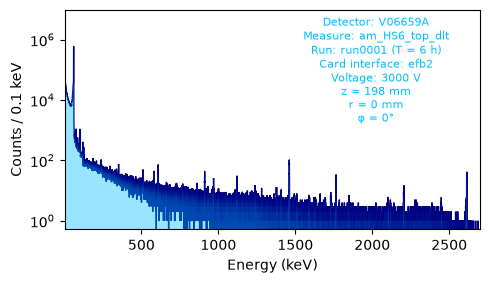

In [32]:
# ============================================================
# PLOT
# ============================================================
plt.figure(figsize=(5, 3))#, dpi = 300)

plt.stairs(
    counts_data,
    bins,
    color="navy",
)
plt.stairs(
    counts_data,
    bins,
    fill = True,
    alpha = 0.4,
    color="deepskyblue",
)

plt.annotate(
    annotation_measure,
    xy=(0.75, 0.97),
    xycoords="axes fraction",
    ha="center",
    va="top",
    multialignment="center",
    fontsize=8,
    zorder=8,
    color="deepskyblue",
)

# axvline non modifica i limiti verticali del grafico
#for energy in peaks.values():
#    plt.axvline(energy, color="red", linewidth=0.8)

#plt.axvline(2615, color="red", linewidth=0.8)

plt.yscale("log")
plt.ylim(0, 1e7)
plt.ylabel(f"Counts / {bins[1] - bins[0]:.1f} keV")
plt.xlabel("Energy (keV)")
plt.xlim(1, 2700)
plt.tight_layout()
plt.show()

# holders anda wraps

In [33]:
detectors = [
    "V03421A",
    "V03422A",
    "V06643A",
    "V06659A",
    "V07298B",
    "V07302A",
    "V07302B",
    "V07647B",
    "V10437B",
    "V10447B",
    "V10784A",
    "V11924A",
    "V11925A",
    "V11947B",
    "V13044A",
    "V13049A",
    "V14618A",
    "V14654A",
    "V14673A",
]

V10784A: cryostat metadata file is missing; holder and wrap dimensions are unavailable.
V13044A: cryostat metadata file is missing; holder and wrap dimensions are unavailable.
V13049A: cryostat metadata file is missing; holder and wrap dimensions are unavailable.
V14618A: cryostat metadata file is missing; holder and wrap dimensions are unavailable.
V14654A: cryostat metadata file is missing; holder and wrap dimensions are unavailable.


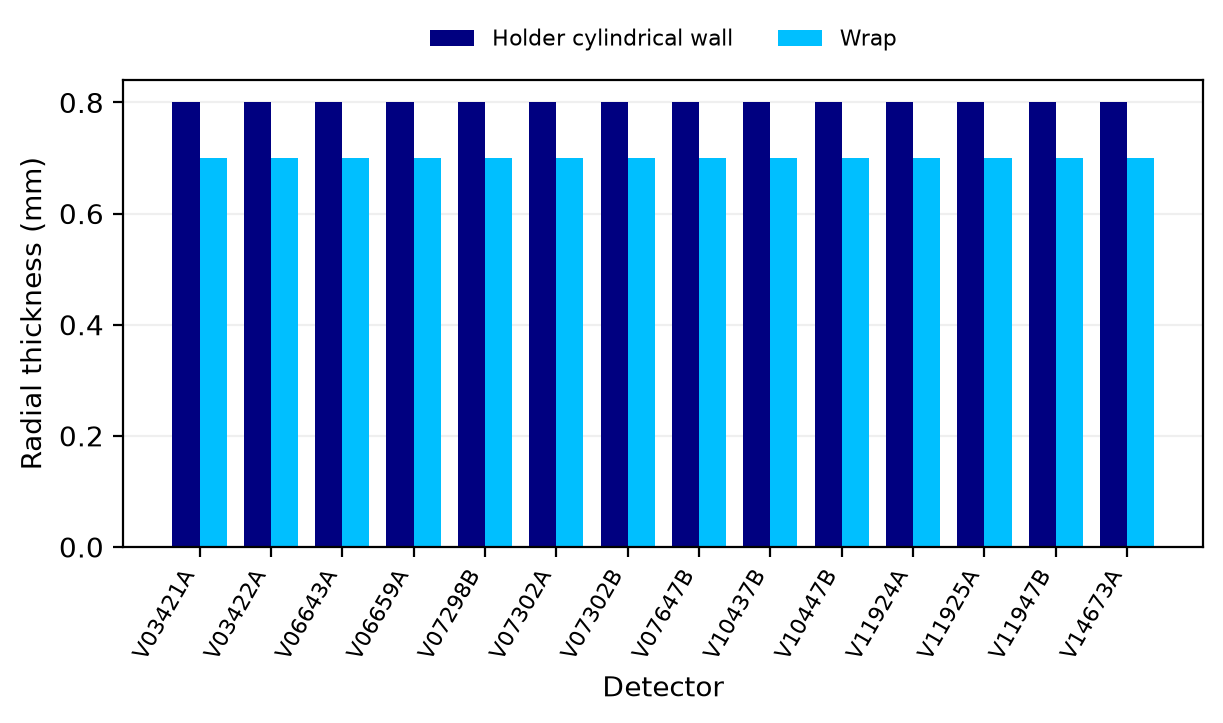

In [34]:

names = []
holder_thicknesses = []
wrap_thicknesses = []



for name in sorted(detectors):
    try:
        cryostat = db.hardware.cryostat[name]

        holder = cryostat["holder"]["geometry"]["cylinder"]
        wrap = cryostat["wrap"]["geometry"]

        holder_thickness = (
            float(holder["outer"]["radius_in_mm"])
            - float(holder["inner"]["radius_in_mm"])
        )

        wrap_thickness = (
            float(wrap["outer"]["radius_in_mm"])
            - float(wrap["inner"]["radius_in_mm"])
        )

        if (
            not np.isfinite([holder_thickness, wrap_thickness]).all()
            or holder_thickness < 0
            or wrap_thickness < 0
        ):
            raise ValueError("Invalid radial thickness.")

        names.append(name)
        holder_thicknesses.append(holder_thickness)
        wrap_thicknesses.append(wrap_thickness)

    except FileNotFoundError:
        print(
            f"{name}: cryostat metadata file is missing; "
            "holder and wrap dimensions are unavailable."
        )

    except (KeyError, TypeError, ValueError) as exc:
        print(
            f"{name}: holder or wrap information is missing "
            f"or invalid in the metadata. Details: {exc}"
        )


if names:
    x = np.arange(len(names))
    width = 0.38

    fig, ax = plt.subplots(
        figsize=(6, 3.5),
        dpi=200,
        layout="constrained",
    )

    ax.bar(
        x - width / 2,
        holder_thicknesses,
        width=width,
        color="navy",
        label="Holder cylindrical wall",
    )

    ax.bar(
        x + width / 2,
        wrap_thicknesses,
        width=width,
        color="deepskyblue",
        label="Wrap",
    )

    ax.set_xticks(x)
    ax.set_xticklabels(
        names,
        rotation=60,
        ha="right",
        fontsize=8,
    )

    ax.set_xlabel("Detector")
    ax.set_ylabel("Radial thickness (mm)")
    ax.legend(
        loc="lower center",
        bbox_to_anchor=(0.5, 1.02),
        ncol=2,
        frameon=False,
        fontsize=8,
    )
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)

    plt.show()
    plt.close(fig)

else:
    print("No valid holder and wrap dimensions were found.")

In [35]:
from pathlib import Path
from importlib.metadata import distribution

missing_detectors = [
    "V13044A",
    "V13049A",
    "V14618A",
    "V14654A",
]

dist = distribution("legend-pygeom-hades")

for detector in missing_detectors:
    matches = [
        Path(dist.locate_file(file))
        for file in (dist.files or [])
        if detector.lower() in str(file).lower()
        and Path(str(file)).suffix.lower() in {
            ".yaml", ".yml", ".json"
        }
    ]

    print(f"\n{detector}")

    if matches:
        for path in matches:
            print(path)
    else:
        print("No matching metadata file found in the installed package.")


V13044A
No matching metadata file found in the installed package.

V13049A
No matching metadata file found in the installed package.

V14618A
No matching metadata file found in the installed package.

V14654A
No matching metadata file found in the installed package.


# Fit

area_peak = 3.83683e+06 ± nan
mu = 59.8537 ± nan
sigma = 0.259614 ± nan
area_left = 100120 ± nan
tau_left = 6.05308 ± nan
area_right = 338280 ± nan
FWHM gaussiana = 0.61134 ± nan keV
Deviance / ndof = 10865.22/121
CHECK FIT: incertezze non identificabili.


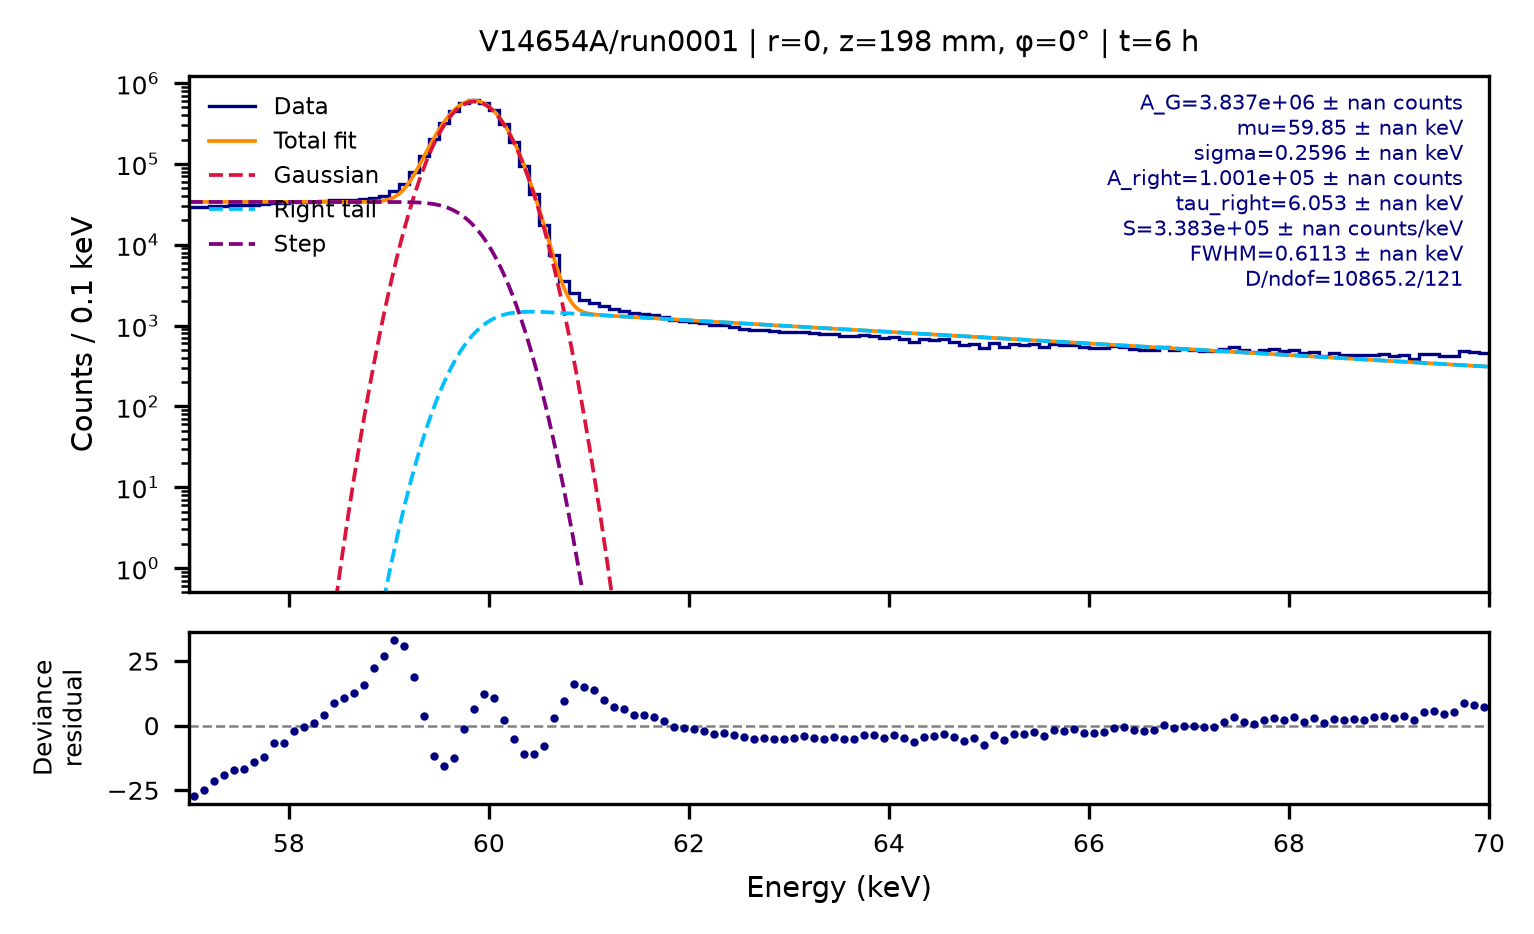

In [58]:
result = fit_am60(
    counts_data,
    bins,
    fit_range=(57, 70),
)

fig = plot_am60_fit(
    result,
    detector,
    run_key,
    meta_data,
)

plt.show()

In [59]:
N60 = result_60['parameters'][0]

In [60]:
result_100 = fit_am_100(counts_data, bins)

In [61]:
N99 = result_100['parameters'][0]
N103 = result_100['parameters'][4]

In [62]:
dpi = 300

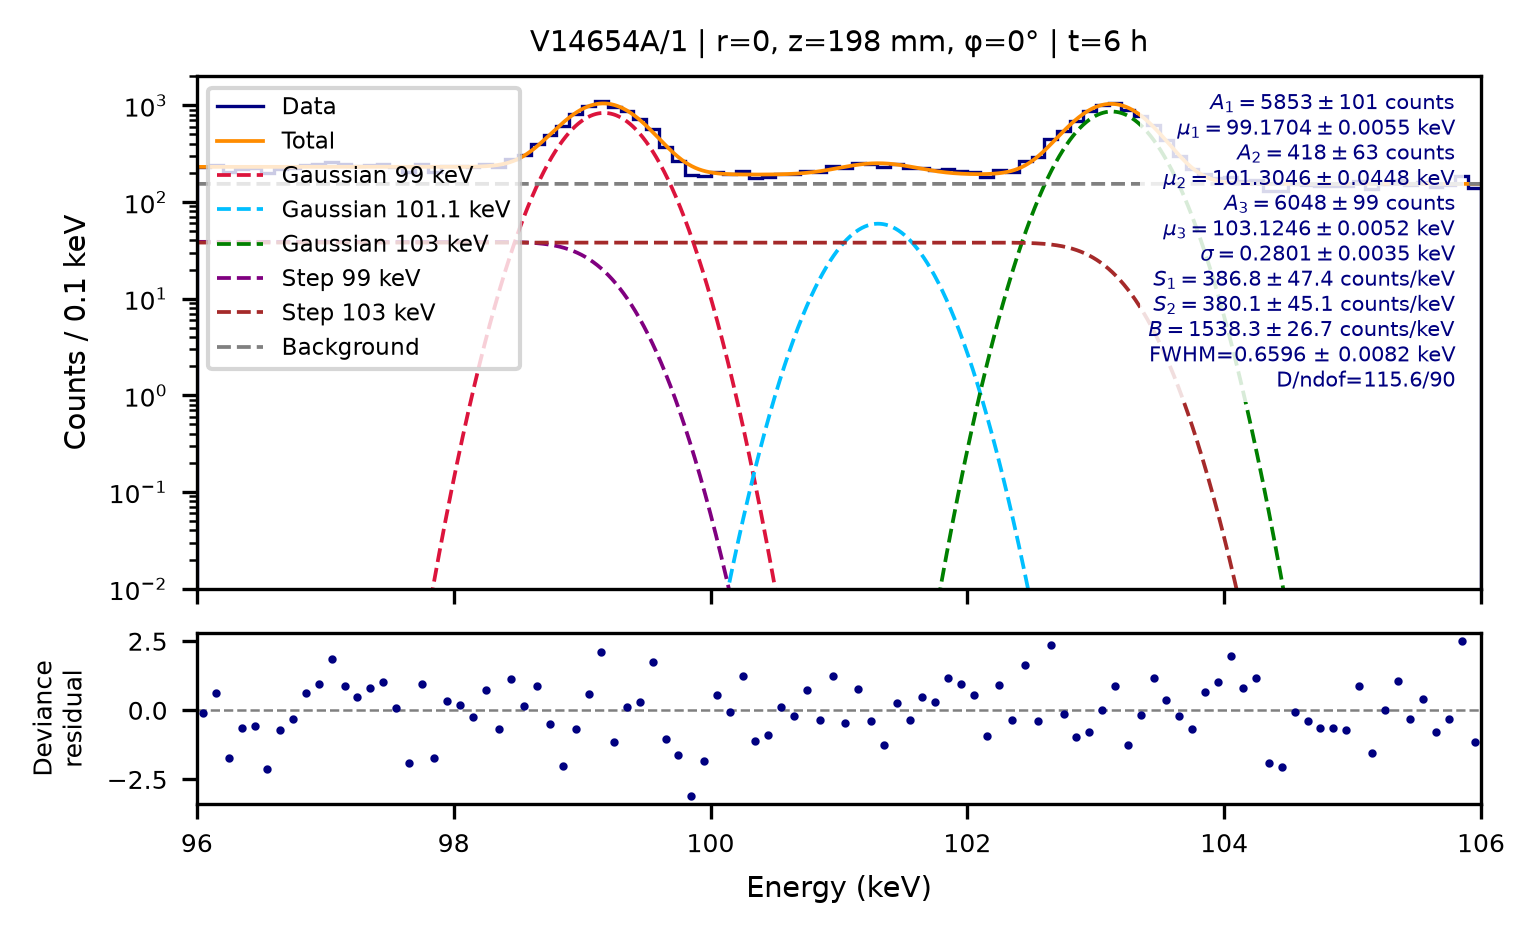

In [68]:
result_100 = fit_am_100(counts_data, bins)
fig = plot_am100_fit(result_100, detector, run, db_data);


In [64]:
O60 = N60 / (N99 + N103)
print(f'experimental counting ratio {O60 :.2f}')

experimental counting ratio 311.31


# ALL DETECTORS

# sigmassss

In [ ]:
# ============================================================
# CONFIGURATION
# ============================================================

base_dir = Path("/global/u2/r/ritaferi/HADES_DATA")

campaign = "c1"
measure = "am_HS1_top_dlt"

# Entrambe navy, con punti vicini:
# v1.1.0 = tondo; v1.2.1 = quadrato.
styles = {
    "v1.1.0": {
        "color": "navy",
        "marker": "o",
        "offset": -0.06,
    },
    "v1.2.1": {
        "color": "orange",
        "marker": "s",
        "offset": 0.06,
    },
}

runs = ["run0001", "run0002", "run0003"]

In [ ]:

# ============================================================
# READ BOTH CSV FILES
# ============================================================

data = {}

for version in styles:
    path = (
        base_dir
        / "spectral_differences"
        / version
        / campaign
        / measure
        / "all_detectors_peak_area_normalized"
        / "fit_parameters.csv"
    )

    if not path.exists():
        print(f"File assente: {path}")
        data[version] = pd.DataFrame(
            columns=["detector", "run", "sigma", "sigma_error"]
        )
        continue

    df = pd.read_csv(path)

    required = {"detector", "run", "sigma", "sigma_error"}
    missing = required - set(df.columns)

    if missing:
        raise ValueError(f"Colonne mancanti in {path}: {missing}")

    for column in ["sigma", "sigma_error"]:
        df[column] = pd.to_numeric(
            df[column],
            errors="coerce",
        )

    valid = (
        np.isfinite(df["sigma"])
        & np.isfinite(df["sigma_error"])
        & (df["sigma"] > 0)
        & (df["sigma_error"] >= 0)
        & df["detector"].notna()
        & df["run"].notna()
    )

    data[version] = df.loc[valid].copy()

    print(
        f"{version}: {valid.sum()} valori validi, "
        f"{(~valid).sum()} esclusi"
    )




In [ ]:
# ============================================================
# ONE PLOT PER RUN
# ============================================================

for run in runs:
    selected = {
        version: df.loc[df["run"] == run].copy()
        for version, df in data.items()
    }

    # Prima i detector presenti in v1.1.0.
    detectors_v1 = sorted(
        set(selected["v1.1.0"]["detector"])
    )

    # Poi quelli presenti solo in v1.2.1.
    other_detectors = sorted(
        set(selected["v1.2.1"]["detector"])
        - set(detectors_v1)
    )

    detectors = detectors_v1 + other_detectors

    if not detectors:
        print(f"Nessun dato per {run}")
        continue

    positions = {
        detector: index
        for index, detector in enumerate(detectors)
    }

    groups = [
        detectors[:3],
        detectors[3:],
    ]

    fig, ax = plt.subplots(
        figsize=(4, 2.5),
        dpi=200,
        layout="constrained",
    )

    for version, df in selected.items():
        if df.empty:
            continue

        style = styles[version]

        x = (
            df["detector"].map(positions).to_numpy()
            + style["offset"]
        )

        ax.errorbar(
            x,
            df["sigma"].to_numpy() * 2.35482,
            yerr=df["sigma_error"].to_numpy() * 2.35482,
            fmt=style["marker"],
            linestyle="none",
            color=style["color"],
            ecolor=style["color"],
            markersize=4,
            capsize=2,
            elinewidth=0.8,
            label=version,
        )

        ax.hlines(
            y=df["sigma"].mean() * 2.35482,
            xmin=x.min() - 0.3,
            xmax=x.max() + 0.3,
            color=style["color"],
            linestyle="--",
            linewidth=1,
        )

    ax.set_xticks(np.arange(len(detectors)))
    ax.set_xticklabels(
        detectors,
        rotation=60,
        ha="right",
        fontsize=7,
    )

    ax.set_xlim(-0.4, len(detectors) - 0.6)

    ax.set_xlabel("Detector", fontsize=9)
    ax.set_ylabel(
        r"FWHM (keV / a.u.)",
        fontsize=8,
    )
    ax.grid(alpha = 0.5, ls = '--') 
    ax.set_title(f"{measure} — {run}", fontsize=9)

    ax.tick_params(axis="y", labelsize=8)

    ax.legend(
        frameon=False,
        fontsize=7,
        labelcolor="linecolor",
    )

    ax.grid(axis="y", alpha=0.2)

    plt.show()
    plt.close(fig)

In [ ]:
# Usa i DataFrame già caricati nel dizionario data.

runs = ["run0001", "run0002", "run0003"]

colors = {
    "v1.1.0": {
        "run0001": "tab:blue",
        "run0002": "navy",
        "run0003": "deepskyblue",
    },
    "v1.2.1": {
        "run0001": "orange",
        "run0002": "red",
        "run0003": "brown",
    },
}

markers = {
    "v1.1.0": "o",
    "v1.2.1": "s",
}

# Piccoli spostamenti per distinguere i sei punti.
offsets = {
    ("v1.1.0", "run0001"): -0.25,
    ("v1.1.0", "run0002"): -0.15,
    ("v1.1.0", "run0003"): -0.05,
    ("v1.2.1", "run0001"): 0.05,
    ("v1.2.1", "run0002"): 0.15,
    ("v1.2.1", "run0003"): 0.25,
}

# Considera soltanto i tre run richiesti.
selected = {
    version: df.loc[df["run"].isin(runs)].copy()
    for version, df in data.items()
}

# Raggruppa a sinistra i detector presenti in v1.1.0.
detectors_v1 = sorted(
    set(selected["v1.1.0"]["detector"])
)

other_detectors = sorted(
    set(selected["v1.2.1"]["detector"])
    - set(detectors_v1)
)

detectors = detectors_v1 + other_detectors

positions = {
    detector: index
    for index, detector in enumerate(detectors)
}

if not detectors:
    print("Nessun dato disponibile.")

else:
    fig, ax = plt.subplots(
        figsize=(5, 3),
        dpi=200,
        layout="constrained",
    )

    for version in ["v1.1.0", "v1.2.1"]:
        for run in runs:
            df = selected[version].loc[
                selected[version]["run"] == run
            ].copy()

            if df.empty:
                continue

            color = colors[version][run]

            x = (
                df["detector"].map(positions).to_numpy()
                + offsets[(version, run)]
            )

            fwhm = df["sigma"].to_numpy() * 2.35482
            fwhm_error = (
                df["sigma_error"].to_numpy() * 2.35482
            )

            ax.errorbar(
                x,
                fwhm,
                yerr=fwhm_error,
                fmt=markers[version],
                linestyle="none",
                color=color,
                ecolor=color,
                markersize=4,
                capsize=2,
                elinewidth=0.8,
                label=f"{version} / {run}",
            )

            ax.hlines(
                y=fwhm.mean(),
                xmin=x.min() - 0.15,
                xmax=x.max() + 0.15,
                color=color,
                linestyle="--",
                linewidth=0.9,
                alpha=0.8,
            )

    ax.set_xticks(np.arange(len(detectors)))
    ax.set_xticklabels(
        detectors,
        rotation=60,
        ha="right",
        fontsize=7,
    )

    ax.set_xlim(-0.5, len(detectors) - 0.5)

    ax.set_xlabel("Detector", fontsize=9)
    ax.set_ylabel("FWHM keV / a.u.", fontsize=9)
    
    ax.tick_params(axis="y", labelsize=8)

    ax.legend(
        frameon=False,
        fontsize=7,
        labelcolor="linecolor",
        ncol=2,
    )

    ax.grid(
        axis="y",
        alpha=0.25,
        linestyle="--",
    )

    plt.show()
    plt.close(fig)

# SOURCE POSITION

In [ ]:
path = (
    Path("/global/u2/r/ritaferi/HADES_DATA")
    / "O60_experimental"
    / version
    / campaign
    / measure
    / "all_results.json"
)

# Coordinata da mostrare nel primo plot: "r", "z" oppure "phi".
position_axis = "z"

# False: conteggi N60; True: conteggi al secondo.
normalize_live_time = False

run_colors = {
    "run0001": "navy",
    "run0002": "orange",
    "run0003": "deepskyblue",
}

position_keys = {
    "r": ("r_in_mm", "Source r (mm)"),
    "z": ("z_in_mm", "Source z (mm)"),
    "phi": ("phi_in_deg", "Source φ (deg)"),
}

with path.open(encoding="utf-8") as stream:
    results = json.load(stream)


def finite_number(value):
    try:
        value = float(value)
    except (TypeError, ValueError):
        return None
    return value if np.isfinite(value) else None



In [ ]:

def finite_number(value):
    try:
        value = float(value)
    except (TypeError, ValueError):
        return None
    return value if np.isfinite(value) else None


def mean_position(values, circular=False):
    if not values:
        return "N/A"

    if circular:
        angles = np.deg2rad(values)
        vector = np.mean(np.exp(1j * angles))

        if abs(vector) < 1e-10:
            return "N/A"

        mean = np.rad2deg(np.angle(vector)) % 360

        if np.isclose(mean, 360):
            mean = 0.0
    else:
        mean = np.mean(values)

    return f"{mean:.1f}"


# ============================================================
# RATIO FOR ALL DETECTORS, COLOURED BY RUN
# results: dizionario già caricato da all_results.json
# ============================================================

run_colors = {
    "run0001": "navy",
    "run0002": "orange",
    "run0003": "deepskyblue",
}

offsets = {
    "run0001": -0.22,
    "run0002": 0.0,
    "run0003": 0.22,
}

detector_list = sorted(
    detector
    for detector, detector_runs in results.items()
    if any(
        finite_number(
            (record.get("ratio") or {}).get("value")
        ) is not None
        for run, record in detector_runs.items()
        if run in run_colors
    )
)

with plt.rc_context({
    "font.size": 11,
    "axes.labelsize": 12,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "axes.edgecolor": "0.35",
    "axes.linewidth": 0.8,
}):
    fig_ratio, ax = plt.subplots(
        figsize=(8, 3),
        layout="constrained",
        dpi=200,
    )

    # Bande alternate per distinguere i detector.
    for index in range(len(detector_list)):
        if index % 2 == 0:
            ax.axvspan(
                index - 0.5,
                index + 0.5,
                color="0.96",
                linewidth=0,
                zorder=0,
            )

    for index, detector in enumerate(detector_list):
        x_line, y_line = [], []

        for run in run_colors:
            record = results[detector].get(run)
            if not record:
                continue

            value = finite_number(
                (record.get("ratio") or {}).get("value")
            )

            if value is None:
                continue

            x_line.append(index + offsets[run])
            y_line.append(value)

        if len(x_line) >= 2:
            ax.plot(
                x_line,
                y_line,
                color="0.5",
                linewidth=1,
                alpha=0.7,
                zorder=2,
            )

    for run, color in run_colors.items():
        x, y, errors = [], [], []

        positions = {
            "r_in_mm": [],
            "z_in_mm": [],
            "phi_in_deg": [],
        }

        for index, detector in enumerate(detector_list):
            record = results[detector].get(run)
            if not record:
                continue

            ratio = record.get("ratio") or {}
            value = finite_number(ratio.get("value"))
            error = finite_number(ratio.get("error"))

            if value is None:
                continue

            x.append(index + offsets[run])
            y.append(value)
            errors.append(
                error
                if error is not None and error >= 0
                else np.nan
            )

            # Posizioni dei soli detector mostrati per questo run.
            pos = (
                (record.get("metadata") or {}).get("source_position")
                or {}
            )

            for key in positions:
                coordinate = finite_number(pos.get(key))
                if coordinate is not None:
                    positions[key].append(coordinate)

        if not x:
            continue

        x = np.asarray(x)
        y = np.asarray(y)
        errors = np.asarray(errors)

        r_mean = mean_position(positions["r_in_mm"])
        z_mean = mean_position(positions["z_in_mm"])
        phi_mean = mean_position(
            positions["phi_in_deg"],
            circular=True,
        )

        run_label = (
            f"Run {int(run[3:])}\n"
            f"⟨r⟩={r_mean} mm, "
            f"⟨z⟩={z_mean} mm, "
            f"⟨φ⟩={phi_mean}°"
        )

        # Tutti i punti, anche quelli senza incertezza disponibile.
        ax.plot(
            x,
            y,
            linestyle="none",
            marker="o",
            color=color,
            markersize=5,
            markeredgecolor="white",
            markeredgewidth=0.5,
            label=run_label,
            zorder=4,
        )

        # Barre d'errore solo dove l'incertezza è disponibile.
        valid_errors = np.isfinite(errors)

        ax.errorbar(
            x[valid_errors],
            y[valid_errors],
            yerr=errors[valid_errors],
            fmt="none",
            ecolor=color,
            elinewidth=1.5,
            capsize=5,
            capthick=1.5,
            zorder=5,
        )

    ax.set_xticks(np.arange(len(detector_list)))
    ax.set_xticklabels(
        detector_list,
        rotation=45,
        ha="right",
        rotation_mode="anchor",
    )

    if detector_list:
        ax.set_xlim(-0.6, len(detector_list) - 0.4)

    ax.set_ylabel(
        r"$N_{60}\,/\,(N_{99}+N_{103})$",
        labelpad=10,
    )
    ax.set_xlabel("Detector", labelpad=10)

    ax.set_axisbelow(True)
    ax.grid(
        axis="y",
        color="0.87",
        linewidth=0.7,
        linestyle="--",
    )

    ax.tick_params(axis="x", length=0, pad=8)
    ax.tick_params(axis="y", direction="out")
    ax.margins(y=0.15)

    if detector_list:
        ax.legend(
            loc="lower left",
            bbox_to_anchor=(0, 1.02, 1, 0),
            mode="expand",
            ncol=3,
            fontsize=8,
            frameon=False,
            borderaxespad=0,
            handletextpad=0.5,
        )

    plt.show()

In [ ]:
db_data.keys()

# Sims

In [163]:
configuration = db.hardware.configuration[detector]["c1"][measure]

In [165]:
import os

In [167]:
output_dir = "/global/u2/r/ritaferi/HADES_DATA"

In [168]:
#run = "run0001"
config_geom = deepcopy(configuration[run])

gdml_file = os.path.join(
    output_dir, f"{detector}_{measure}_{run}.gdml"
)

if os.path.isfile(gdml_file):
    reg = gdml.Reader(gdml_file).getRegistry()
    print(f"GDML già presente, caricato: {gdml_file}")
else:
    reg = pygeomhades.core.construct(config_geom)
    os.makedirs(output_dir, exist_ok=True)
    write_pygeom(reg, gdml_file)
    print(f"GDML creato: {gdml_file}")

Cloning git@github.com:legend-exp/hades-metadata in /tmp/hades-metadata-ritaferi...
Checking out the latest stable tag (v0.2.0)...


GDML creato: /global/u2/r/ritaferi/HADES_DATA/V03421A_am_HS6_top_dlt_run0002.gdml


In [170]:

def collect_global_placements(logical_volume, parent_matrix=None):
    """
    Percorre ricorsivamente il GDML e restituisce la trasformazione
    globale di ogni volume fisico.
    """
    if parent_matrix is None:
        parent_matrix = np.eye(4)

    placements = {}

    def walk(mother_lv, mother_matrix):
        for pv in mother_lv.daughterVolumes:
            local_matrix = physical_volume_matrix(pv)
            global_matrix = mother_matrix @ local_matrix

            logical_name = pv.logicalVolume.name

            placements.setdefault(logical_name, []).append({
                "physical_name": pv.name,
                "logical_volume": pv.logicalVolume,
                "matrix": global_matrix,
            })

            walk(pv.logicalVolume, global_matrix)

    walk(logical_volume, parent_matrix)

    return placements


def find_germanium_detector(reg):
    candidates = []

    for name, lv in reg.logicalVolumeDict.items():
        material_name = getattr(lv.material, "name", str(lv.material))

        if "Germanium" in material_name:
            candidates.append(name)

    if len(candidates) == 0:
        raise ValueError("Nessun detector al germanio trovato")

    if len(candidates) > 1:
        print("Detector al germanio trovati:", candidates)

    return candidates[0]



def find_source(reg):
    candidates = []

    for name, lv in reg.logicalVolumeDict.items():
        material_name = getattr(lv.material, "name", str(lv.material))

        if "Source" in material_name:
            candidates.append(name)

    if len(candidates) == 0:
        raise ValueError("Nessuna sorgente trovate")

    if len(candidates) > 1:
        print("Sorgente trovata:", candidates)

    return candidates[0]

def tubs_profile(solid):
    """Profilo r-z di un cilindro Tubs."""

    rmin = float(solid.evaluateParameterWithUnits("pRMin"))
    rmax = float(solid.evaluateParameterWithUnits("pRMax"))
    dz = float(solid.evaluateParameterWithUnits("pDz"))

    # pDz è la lunghezza totale lungo z
    zmin = -dz / 2
    zmax = dz / 2

    r = np.array([
        rmin,
        rmax,
        rmax,
        rmin,
        rmin
    ])

    z = np.array([
        zmin,
        zmin,
        zmax,
        zmax,
        zmin
    ])

    return r, z

def box_profile(solid):
    """Profilo nel piano locale x-z di un Box."""

    size_x = float(solid.evaluateParameterWithUnits("pX"))
    size_z = float(solid.evaluateParameterWithUnits("pZ"))

    xmin = -size_x / 2
    xmax = size_x / 2
    zmin = -size_z / 2
    zmax = size_z / 2

    r = np.array([
        xmin,
        xmax,
        xmax,
        xmin,
        xmin
    ])

    z = np.array([
        zmin,
        zmin,
        zmax,
        zmax,
        zmin
    ])

    return r, z

def transform_profile(r, z, matrix):
    """
    Trasforma un profilo locale (r, z) nelle coordinate globali.

    Parameters
    ----------
    r : array-like
        Coordinate radiali locali.
    z : array-like
        Coordinate verticali locali.
    matrix : array-like, shape (4, 4)
        Matrice omogenea contenente rotazione e traslazione globali.

    Returns
    -------
    radius : ndarray
        Distanza globale dall'asse z.
    height : ndarray
        Coordinata z globale.
    """

    r = np.asarray(r, dtype=float)
    z = np.asarray(z, dtype=float)

    # Punti omogenei locali: (x=r, y=0, z, 1)
    points = np.column_stack([
        r,
        np.zeros_like(r),
        z,
        np.ones_like(r)
    ])

    # Trasformazione nelle coordinate globali
    transformed = (matrix @ points.T).T

    x_global = transformed[:, 0]
    y_global = transformed[:, 1]
    z_global = transformed[:, 2]

    radius = np.sqrt(x_global**2 + y_global**2)
    height = z_global
    
    return radius, height

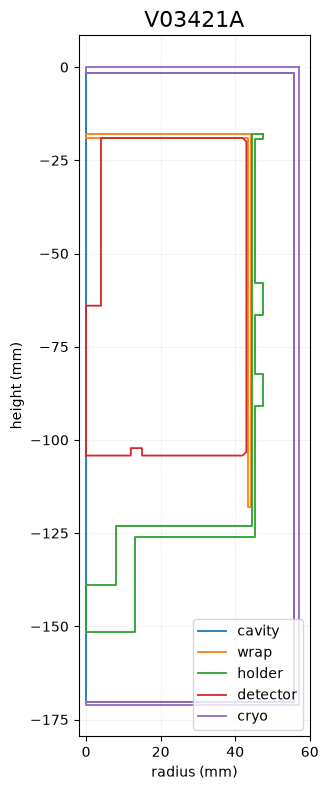

In [172]:
def generic_polycone_profile(solid):
    r = np.asarray(
        solid.evaluateParameterWithUnits("pR"),
        dtype=float
    )
    z = np.asarray(
        solid.evaluateParameterWithUnits("pZ"),
        dtype=float
    )

    return np.append(r, r[0]), np.append(z, z[0])


def polycone_profile(solid):
    z = np.asarray(
        solid.evaluateParameterWithUnits("pZpl"),
        dtype=float
    )
    rmin = np.asarray(
        solid.evaluateParameterWithUnits("pRMin"),
        dtype=float
    )
    rmax = np.asarray(
        solid.evaluateParameterWithUnits("pRMax"),
        dtype=float
    )

    r = np.concatenate([rmax, rmin[::-1], [rmax[0]]])
    z = np.concatenate([z, z[::-1], [z[0]]])

    return r, z

    
def get_profile(solid):
    solid_type = str(solid.type).lower()

    if "genericpolycone" in solid_type:
        return generic_polycone_profile(solid)

    if "polycone" in solid_type:
        return polycone_profile(solid)

    if "tubs" in solid_type or "tube" in solid_type:
        return tubs_profile(solid)

    if "box" in solid_type:
        return box_profile(solid)

    raise TypeError(
        f"Solido {solid.name} di tipo {solid.type} non supportato"
    )

def evaluate_vector(vector):
    """Converte Position o Rotation di pyg4ometry in array numerico."""
    return np.asarray(vector.eval(), dtype=float)


def physical_volume_matrix(pv):
    """Matrice omogenea della trasformazione del PhysicalVolume."""
    position = evaluate_vector(pv.position)
    rotation = evaluate_vector(pv.rotation)

    rotation_matrix = np.linalg.inv(
        pg4.transformation.tbxyz2matrix(rotation)
    )

    matrix = np.eye(4)
    matrix[:3, :3] = rotation_matrix
    matrix[:3, 3] = position

    return matrix

placements = collect_global_placements(reg.getWorldVolume())

detector_name = find_germanium_detector(reg)

components = {
    "cavity_lv": {
        "label": "cavity",
        "color": "tab:blue"
    },
    "Wrap": {
        "label": "wrap",
        "color": "tab:orange"
    },
    "Holder": {
        "label": "holder",
        "color": "tab:green"
    },
    detector_name: {
        "label": "detector",
        "color": "tab:red"
    },
    "Cryostat": {
        "label": "cryo",
        "color": "tab:purple"
    },
}

fig, ax = plt.subplots(figsize=(4,8))

for logical_name, style in components.items():

    if logical_name not in placements:
        print(f"Volume non trovato: {logical_name}")
        continue

    # Se esistono più copie, le disegna tutte
    for index, placement in enumerate(placements[logical_name]):

        lv = placement["logical_volume"]
        matrix = placement["matrix"]

        try:
            r_local, z_local = get_profile(lv.solid)
        except TypeError as error:
            print(error)
            continue

        radius, height = transform_profile(
            r_local,
            z_local,
            matrix
        )

        # Una sola voce in legenda per componente
        label = style["label"] if index == 0 else None

        ax.plot(
            radius,
            height,
            color=style["color"],
            linewidth=1.3,
            label=label
        )

ax.set_title(detector_name, fontsize=16)
ax.set_xlabel("radius (mm)")
ax.set_ylabel("height (mm)")

ax.set_xlim(left=-2)
ax.set_aspect("equal", adjustable="box")

ax.grid(alpha=0.15)
ax.legend(loc = 'lower right')

plt.tight_layout()
plt.show()

In [174]:
peaks = {
    "gamma_59p9keV": 59.9,
    "gamma_99keV": 99.0,
    "gamma_103keV": 103.0,
    "gamma_123p1keV": 123.1,
    "gamma_125p3keV": 125.3,
    "gamma_208p1keV": 208.1,
    "gamma_335p4keV": 335.4,
    "gamma_662p4keV": 662.4,
}

N_sim = 100


force_rerun = False

os.makedirs(output_dir, exist_ok=True)
simulation_files = {}

for name, energy_keV in peaks.items():

    output_file = os.path.join(
        output_dir,
        f"{detector}_{measure}_{run}_{name}.lh5"
    )

    if os.path.isfile(output_file) and not force_rerun:
        simulation_files[name] = output_file
        print(f"✅ {name}: uso il file esistente → {output_file}")
        continue

    macro = [
        "/RMG/Manager/Logging/LogLevel summary",
        "/RMG/Processes/HadronicPhysics Shielding",
        f"/RMG/Geometry/RegisterDetector Germanium {detector} 1",
        "/RMG/Output/NtupleUseVolumeName true",
        "/RMG/Output/NtuplePerDetector false",
        "/run/initialize",
        "/RMG/Generator/Confine Volume",
        "/RMG/Generator/Confinement/Physical/AddVolume Source_PV",
        "/RMG/Generator/Select GPS",
        "/gps/particle gamma",
        "/gps/ene/type Mono",
        f"/gps/energy {energy_keV} keV",
        "/gps/ang/type iso",
        f"/run/beamOn {N_sim}",
    ]

    print(f"▶ {name}: avvio simulazione → {output_file}")

    try:
        remage_run(
            macros=macro,
            gdml_files=gdml_file,
            output=output_file,
            overwrite_output=True,
        )
        simulation_files[name] = output_file
        print(f"✅ {name}: simulazione completata")

    except Exception as e:
        print(f"❌ {name}: {e}")

print("\nFile disponibili:", simulation_files)

[Summary -> CLHEP::HepRandom seed changed to: 111297878 (from system entropy)
[Summary -> Checking for overlaps in GDML geometry...


▶ gamma_59p9keV: avvio simulazione → /global/u2/r/ritaferi/HADES_DATA/V03421A_am_HS6_top_dlt_run0002_gamma_59p9keV.lh5
  _ __ ___ _ __ ___   __ _  __ _  ___ 
 | '__/ _ \ '_ ` _ \ / _` |/ _` |/ _ \
 | | |  __/ | | | | | (_| | (_| |  __/ v1.1.0
 |_|  \___|_| |_| |_|\__,_|\__, |\___| using geant4-11-03-patch-02 [MT]
                           |___/      

G4GDML: Reading '/global/u2/r/ritaferi/HADES_DATA/V03421A_am_HS6_top_dlt_run0002.gdml'...
G4GDML: Reading definitions...
G4GDML: Reading materials...
G4GDML: Reading solids...
G4GDML: Reading structure...
G4GDML: Reading userinfo...
G4GDML: Reading setup...
G4GDML: Reading '/global/u2/r/ritaferi/HADES_DATA/V03421A_am_HS6_top_dlt_run0002.gdml' done!
Stripping off GDML names of materials, solids and volumes ...

-------- WWWW ------- G4Exception-START -------- WWWW -------
*** G4Exception : GeomVol1002
      issued by : G4PVPlacement::CheckOverlaps()
Overlap with volume already placed !
          Overlap is detected for volume cavity_pv:0 

[Summary -> Opening output file: /global/u2/r/ritaferi/HADES_DATA/.rmg-tmp-65834.V03421A_am_HS6_top_dlt_run0002_gamma_59p9keV.hdf5 (for /global/u2/r/ritaferi/HADES_DATA/V03421A_am_HS6_top_dlt_run0002_gamma_59p9keV.lh5)
[Summary -> Starting run nr. 0. Current local time is 14-10-2026 08:13:37 PDT
[Summary -> Number of events to be processed: 100
[Summary -> Processing event nr. 10 (10%), at 0 days, 0 hours, 0 minutes and 0 seconds
[Summary -> Processing event nr. 20 (20%), at 0 days, 0 hours, 0 minutes and 0 seconds
[Summary -> Processing event nr. 30 (30%), at 0 days, 0 hours, 0 minutes and 0 seconds
[Summary -> Processing event nr. 40 (40%), at 0 days, 0 hours, 0 minutes and 0 seconds
[Summary -> Processing event nr. 50 (50%), at 0 days, 0 hours, 0 minutes and 0 seconds
[Summary -> Processing event nr. 60 (60%), at 0 days, 0 hours, 0 minutes and 0 seconds
[Summary -> Processing event nr. 70 (70%), at 0 days, 0 hours, 0 minutes and 0 seconds
[Summary -> Processing event nr. 80 (80%), a

✅ gamma_59p9keV: simulazione completata
▶ gamma_99keV: avvio simulazione → /global/u2/r/ritaferi/HADES_DATA/V03421A_am_HS6_top_dlt_run0002_gamma_99keV.lh5
  _ __ ___ _ __ ___   __ _  __ _  ___ 
 | '__/ _ \ '_ ` _ \ / _` |/ _` |/ _ \
 | | |  __/ | | | | | (_| | (_| |  __/ v1.1.0
 |_|  \___|_| |_| |_|\__,_|\__, |\___| using geant4-11-03-patch-02 [MT]
                           |___/      

G4GDML: Reading '/global/u2/r/ritaferi/HADES_DATA/V03421A_am_HS6_top_dlt_run0002.gdml'...
G4GDML: Reading definitions...
G4GDML: Reading materials...
G4GDML: Reading solids...
G4GDML: Reading structure...
G4GDML: Reading userinfo...
G4GDML: Reading setup...
G4GDML: Reading '/global/u2/r/ritaferi/HADES_DATA/V03421A_am_HS6_top_dlt_run0002.gdml' done!
Stripping off GDML names of materials, solids and volumes ...

-------- WWWW ------- G4Exception-START -------- WWWW -------
*** G4Exception : GeomVol1002
      issued by : G4PVPlacement::CheckOverlaps()
Overlap with volume already placed !
          Overlap

[Summary -> Opening output file: /global/u2/r/ritaferi/HADES_DATA/.rmg-tmp-10169.V03421A_am_HS6_top_dlt_run0002_gamma_99keV.hdf5 (for /global/u2/r/ritaferi/HADES_DATA/V03421A_am_HS6_top_dlt_run0002_gamma_99keV.lh5)
[Summary -> Starting run nr. 0. Current local time is 14-10-2026 08:13:46 PDT
[Summary -> Number of events to be processed: 100
[Summary -> Processing event nr. 10 (10%), at 0 days, 0 hours, 0 minutes and 0 seconds
[Summary -> Processing event nr. 20 (20%), at 0 days, 0 hours, 0 minutes and 0 seconds
[Summary -> Processing event nr. 30 (30%), at 0 days, 0 hours, 0 minutes and 0 seconds
[Summary -> Processing event nr. 40 (40%), at 0 days, 0 hours, 0 minutes and 0 seconds
[Summary -> Processing event nr. 50 (50%), at 0 days, 0 hours, 0 minutes and 0 seconds
[Summary -> Processing event nr. 60 (60%), at 0 days, 0 hours, 0 minutes and 0 seconds
[Summary -> Processing event nr. 70 (70%), at 0 days, 0 hours, 0 minutes and 0 seconds
[Summary -> Processing event nr. 80 (80%), at 0 

...

[Summary -> Opening output file: /global/u2/r/ritaferi/HADES_DATA/.rmg-tmp-83494.V03421A_am_HS6_top_dlt_run0002_gamma_103keV.hdf5 (for /global/u2/r/ritaferi/HADES_DATA/V03421A_am_HS6_top_dlt_run0002_gamma_103keV.lh5)
[Summary -> Starting run nr. 0. Current local time is 14-10-2026 08:13:55 PDT
[Summary -> Number of events to be processed: 100
[Summary -> Processing event nr. 10 (10%), at 0 days, 0 hours, 0 minutes and 0 seconds
[Summary -> Processing event nr. 20 (20%), at 0 days, 0 hours, 0 minutes and 0 seconds
[Summary -> Processing event nr. 30 (30%), at 0 days, 0 hours, 0 minutes and 0 seconds
[Summary -> Processing event nr. 40 (40%), at 0 days, 0 hours, 0 minutes and 0 seconds
[Summary -> Processing event nr. 50 (50%), at 0 days, 0 hours, 0 minutes and 0 seconds
[Summary -> Processing event nr. 60 (60%), at 0 days, 0 hours, 0 minutes and 0 seconds
[Summary -> Processing event nr. 70 (70%), at 0 days, 0 hours, 0 minutes and 0 seconds
[Summary -> Processing event nr. 80 (80%), at 

✅ gamma_103keV: simulazione completata
▶ gamma_123p1keV: avvio simulazione → /global/u2/r/ritaferi/HADES_DATA/V03421A_am_HS6_top_dlt_run0002_gamma_123p1keV.lh5
  _ __ ___ _ __ ___   __ _  __ _  ___ 
 | '__/ _ \ '_ ` _ \ / _` |/ _` |/ _ \
 | | |  __/ | | | | | (_| | (_| |  __/ v1.1.0
 |_|  \___|_| |_| |_|\__,_|\__, |\___| using geant4-11-03-patch-02 [MT]
                           |___/      

G4GDML: Reading '/global/u2/r/ritaferi/HADES_DATA/V03421A_am_HS6_top_dlt_run0002.gdml'...
G4GDML: Reading definitions...
G4GDML: Reading materials...
G4GDML: Reading solids...
G4GDML: Reading structure...
G4GDML: Reading userinfo...
G4GDML: Reading setup...
G4GDML: Reading '/global/u2/r/ritaferi/HADES_DATA/V03421A_am_HS6_top_dlt_run0002.gdml' done!
Stripping off GDML names of materials, solids and volumes ...

-------- WWWW ------- G4Exception-START -------- WWWW -------
*** G4Exception : GeomVol1002
      issued by : G4PVPlacement::CheckOverlaps()
Overlap with volume already placed !
          Ov

[Summary -> CLHEP::HepRandom seed changed to: 1236280526 (from system entropy)
[Summary -> Checking for overlaps in GDML geometry...


❌ gamma_125p3keV: error while running remage-cpp
▶ gamma_208p1keV: avvio simulazione → /global/u2/r/ritaferi/HADES_DATA/V03421A_am_HS6_top_dlt_run0002_gamma_208p1keV.lh5
  _ __ ___ _ __ ___   __ _  __ _  ___ 
 | '__/ _ \ '_ ` _ \ / _` |/ _` |/ _ \
 | | |  __/ | | | | | (_| | (_| |  __/ v1.1.0
 |_|  \___|_| |_| |_|\__,_|\__, |\___| using geant4-11-03-patch-02 [MT]
                           |___/      

G4GDML: Reading '/global/u2/r/ritaferi/HADES_DATA/V03421A_am_HS6_top_dlt_run0002.gdml'...
G4GDML: Reading definitions...
G4GDML: Reading materials...
G4GDML: Reading solids...
G4GDML: Reading structure...
G4GDML: Reading userinfo...
G4GDML: Reading setup...
G4GDML: Reading '/global/u2/r/ritaferi/HADES_DATA/V03421A_am_HS6_top_dlt_run0002.gdml' done!
Stripping off GDML names of materials, solids and volumes ...

-------- WWWW ------- G4Exception-START -------- WWWW -------
*** G4Exception : GeomVol1002
      issued by : G4PVPlacement::CheckOverlaps()
Overlap with volume already placed !
  

[Summary -> CLHEP::HepRandom seed changed to: 1235076021 (from system entropy)
[Summary -> Checking for overlaps in GDML geometry...


In [ ]:
N_sim_by_peak = {}
energies = ["gamma_59p9keV", "gamma_99keV","gamma_103keV",
    "gamma_123p1keV",
    "gamma_125p3keV",
    "gamma_208p1keV",
    "gamma_335p4keV"]

for name in energies:
    filename = os.path.join(
        output_dir, f"{detector}_{measure}_{run}_{name}.lh5"
    )

    obj = lh5.read("number_of_simulated_events", filename)

    # Compatibilità con versioni che restituiscono una tupla
    if isinstance(obj, tuple):
        obj = obj[0]

    N_sim_by_peak[name] = int(obj.value)
    print(f"{name}: {N_sim_by_peak[name]:,} eventi simulati")

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4))
has_counts = False

for i, (name, energy_keV) in enumerate(peaks.items()):

    filename = simulation_files.get(
        name,
        os.path.join(
            output_dir,
            f"{detector}_{measure}_{run}_{name}.lh5"
        )
    )

    print("PATH:", filename, "| esiste:", os.path.isfile(filename))

    try:
        data = lh5.read_as("stp/germanium", filename, "ak")
        energy = ak.to_numpy(ak.sum(data.edep, axis=-1))
        energy = energy[energy > 0]

        counts, _ = np.histogram(energy, bins=bins)

        if counts.sum() == 0:
            print(f"{name}: nessun deposito nell'intervallo del grafico")
            continue

        ax.stairs(
            counts,
            bins,
            #color=colors[i % len(colors)],
            label=f"{energy_keV:g} keV"
        )
        has_counts = True

    except Exception:
        print(f"Errore durante la lettura o il grafico di {name}:")
        traceback.print_exc()

if has_counts:
    ax.set_xlabel("Energy deposited [keV]")
    ax.set_ylabel("Counts / 1 keV")
    ax.set_xlim(emin, emax)
    ax.set_yscale("log")
    ax.legend(title="Gamma generato")
    fig.tight_layout()
    plt.show()
else:
    plt.close(fig)
    print("Nessun conteggio da mostrare")

In [ ]:
BR = {
    "gamma_59p9keV":  0.359,
    "gamma_99keV":    2.03e-4,
    "gamma_103keV":   1.95e-4,
    "gamma_123p1keV": 1.00e-5,
    "gamma_125p3keV": 4.08e-5,
    "gamma_208p1keV": 7.91e-6,
    "gamma_335p4keV": 4.96e-6,
}


In [ ]:

activity = 4330e3  # Bq: valore nominale comune alla misura

counts_theory = np.zeros(len(bins) - 1)
counts_smeared = np.zeros(len(bins) - 1)

for name, br in BR.items():

    filename = os.path.join(
        output_dir, f"{detector}_{measure}_{run}_{name}.lh5"
    )

    # Gli errori di lettura vengono mostrati, evitando somme incomplete
    data = lh5.read_as("stp/germanium", filename, "ak")
    energy = ak.to_numpy(ak.sum(data.edep, axis=-1))
    energy = energy[energy > 0]

    if len(energy) == 0:
        print(f"{name}: nessun deposito positivo di energia")
        continue

    energy_smeared = ak.to_numpy(
        reboost.math.stats.gaussian_sample(energy, sigma=1)
    )

    N_sim = N_sim_by_peak[name]
    if N_sim <= 0:
        raise ValueError(f"{name}: N_sim deve essere positivo")

    # BR applicato una sola volta, nel peso
    peso = activity * time_measurement * br / N_sim
    weights = np.full(len(energy), peso)

    counts_iso, _ = np.histogram(
        energy, bins=bins, weights=weights
    )
    counts_iso_smeared, _ = np.histogram(
        energy_smeared, bins=bins, weights=weights
    )

    counts_theory += counts_iso
    counts_smeared += counts_iso_smeared

    print(f"{name}: N_sim = {N_sim:,}, peso = {peso:.6g}")

counts_MC = counts_smeared